# Лабораторная работа 6. Чёрный ящик и трансферируемость атак: transfer-based, score-based, decision-based методы

**Курс:** Машинное обучение. Безопасность ИИ-систем

**По материалам лекции 5**


**Среда:** Python, PyTorch, torchvision


## Цель работы
Закрепить методы построения adversarial-примеров в условиях ограниченного доступа к целевой модели и научиться сравнивать transfer-based, score-based и decision-based атаки по успешности, числу запросов и величине вносимого искажения.

## Результаты обучения
После выполнения работы вы должны уметь:
- обучать суррогатную модель через запросы к оракулу и переносить на неё белоящичную атаку (transfer-based);
- реализовывать оценку градиента через запросы confidence-баллов методом конечных разностей (ZOO) и методом случайной выборки (NES);
- реализовывать decision-based атаку (Boundary Attack), работающую только с итоговой меткой класса;
- сравнивать три класса чёрно-ящичных атак по критерию «качество атаки / стоимость запросов» и обосновывать выбор метода под конкретный сценарий доступа к API.

## Как пользоваться этим ноутбуком
- Ячейки с `# TODO` необходимо заполнить самостоятельно.
- Ячейки с текстом **"Вопрос для отчёта"** требуют письменного ответа в markdown-ячейке ниже.
- Перед сдачей: Kernel → Restart & Run All, ноутбук должен выполняться от начала до конца без ошибок.
- Все атаки в этой работе взаимодействуют с целевой моделью только через специальный объект-оракул — прямой доступ к её параметрам и градиентам запрещён по условию задания (это имитирует реальный чёрный ящик).


## 0. Подготовка окружения

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import pandas as pd
import time

RANDOM_STATE = 42
torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

# Русские названия цифр MNIST
RU_DIGIT_NAMES = {
    0: 'ноль', 1: 'один', 2: 'два', 3: 'три', 4: 'четыре',
    5: 'пять', 6: 'шесть', 7: 'семь', 8: 'восемь', 9: 'девять'
}

Device: cpu


## Часть I. Целевая модель и оракул

**Задание:** загрузите MNIST, обучите CNN-классификатор (2 свёрточных слоя + полносвязный классификатор) — эта модель будет играть роль "чёрного ящика". Затем реализуйте класс-обёртку `QueryCounter`, через который ВСЕ последующие атаки должны обращаться к модели — прямой вызов `target_model(x)` в атаках запрещён, чтобы корректно считать число запросов.

In [ ]:
transform = transforms.Compose([transforms.ToTensor()])
train_dataset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset  = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=256, shuffle=False)
print(f"Train: {len(train_dataset)}, Test: {len(test_dataset)}")
print("Классы (рус.):", [RU_DIGIT_NAMES[i] for i in range(10)])

Train: 60000, Test: 10000
Классы (рус.): ['ноль', 'один', 'два', 'три', 'четыре', 'пять', 'шесть', 'семь', 'восемь', 'девять']


In [ ]:
import torch.nn as nn
import torch.nn.functional as F

# TODO: реализуйте класс TargetCNN (2 свёрточных слоя, max pooling, полносвязный классификатор)
# TODO: реализуйте класс TargetCNN (2 свёрточных слоя, max pooling, полносвязный классификатор)
class TargetCNN(nn.Module):
    def __init__(self):
        super().__init__()
        # TODO: определите слои
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        # TODO: реализуйте прямой проход
        x = F.relu(self.conv1(x))
        x = F.max_pool2d(x, 2)
        x = F.relu(self.conv2(x))
        x = F.max_pool2d(x, 2)
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)
    # TODO: определите слои
    # TODO: реализуйте прямой проход
    # pass

In [ ]:
# TODO: обучите target_model на train_loader (2-3 эпохи)
target_model = None  # TODO
opt = None  # TODO
crit = None  # TODO

target_model = TargetCNN().to(device)
opt = torch.optim.Adam(target_model.parameters(), lr=1e-3)
crit = nn.CrossEntropyLoss()

# TODO: цикл обучения
for epoch in range(2):
    target_model.train()
    running_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad()
        loss = crit(target_model(xb), yb)
        loss.backward()
        opt.step()
        running_loss += loss.item()
    print(f"Эпоха {epoch+1}: loss={running_loss/len(train_loader):.4f}")

Эпоха 1: loss=0.2545
Эпоха 2: loss=0.0616


In [ ]:
# TODO: оцените clean accuracy на тестовой выборке
clean_accuracy = None  # TODO

target_model.eval()
correct, total = 0, 0
with torch.no_grad():
    for xb, yb in test_loader:
        xb, yb = xb.to(device), yb.to(device)
        correct += (target_model(xb).argmax(1) == yb).sum().item()
        total += yb.size(0)
clean_accuracy = correct / total
print(f"Clean accuracy: {clean_accuracy:.4f}")

Clean accuracy: 0.9866


**Задание:** реализуйте класс `QueryCounter`, который считает число обращений к модели и предоставляет три уровня доступа:
- `logits(x)` — полные логиты (используется только для white-box эталона в Части V, НЕ для чёрно-ящичных атак);
- `probs(x)` — вероятности классов (softmax) — доступ уровня score-based;
- `label(x)` — только индекс предсказанного класса — доступ уровня decision-based.

Каждый вызов любого из трёх методов должен увеличивать счётчик `n_queries` на размер батча.

In [ ]:
# TODO: реализуйте класс QueryCounter
class QueryCounter:
    def __init__(self, model):
        self.model = model
        self.n_queries = 0

    def reset(self):
        self.n_queries = 0

    def logits(self, x):
        # TODO: увеличьте счётчик запросов, верните логиты модели (без градиента)
        self.n_queries += x.size(0)
        with torch.no_grad():
            return self.model(x)

    def probs(self, x):
        # TODO: используйте self.logits и softmax
        return F.softmax(self.logits(x), dim=1)

    def label(self, x):
        # TODO: используйте self.logits и argmax
        return self.logits(x).argmax(1)

oracle = QueryCounter(target_model)

## Часть II. Transfer-based атака

### 2.1. Обучение суррогатной модели через оракул

**Задание:** реализуйте суррогатную модель с архитектурой, отличной от целевой (например, полносвязная сеть вместо CNN), и обучите её по схеме Papernot et al.:

1. Соберите небольшой начальный набор данных (например, 20 примеров на класс) без использования меток из исходного датасета — размечайте их исключительно через `oracle.label(x)`.
2. Обучите суррогат на текущем наборе.
3. Постройте аугментацию данных по знаку якобиана суррогатной модели:

$ S_{\rho+1} = \left\{ \tilde{x} + \lambda \cdot \text{sign}\left(J_F[\tilde{O}(\tilde{x})]\right) : \tilde{x} \in S_\rho \right\} \cup S_\rho $

1. Разметьте новые примеры через `oracle.label` и повторите цикл несколько раундов (например, 5-6).

In [ ]:
# TODO: реализуйте класс SubstituteMLP — архитектура должна отличаться от TargetCNN
class SubstituteMLP(nn.Module):
    def __init__(self):
        super().__init__()
        # TODO: определите полносвязные слои
        self.fc1 = nn.Linear(28 * 28, 256)
        self.fc2 = nn.Linear(256, 128)
        self.fc3 = nn.Linear(128, 10)

    def forward(self, x):
        # TODO
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)

In [ ]:
# TODO: соберите начальный набор данных (n_seed_per_class примеров на класс из train_dataset,
# ИСПОЛЬЗУЯ ТОЛЬКО ИЗОБРАЖЕНИЯ, метки получите через oracle.label)

oracle.reset()
n_seed_per_class = 20
substitute_data = None  # TODO
oracle_labels = None  # TODO: oracle.label(substitute_data)

seed_indices = []
for c in range(10):
    idx = (train_dataset.targets == c).nonzero(as_tuple=True)[0][:n_seed_per_class]
    seed_indices.append(idx)
seed_indices = torch.cat(seed_indices)

substitute_data = (train_dataset.data[seed_indices].float().unsqueeze(1) / 255.0).to(device)
oracle_labels = oracle.label(substitute_data)
print(f"Начальный набор: {substitute_data.shape}, запросов к оракулу = {oracle.n_queries}")
print("Пример русских меток:", [RU_DIGIT_NAMES[i] for i in oracle_labels[:5].tolist()])

Начальный набор: torch.Size([200, 1, 28, 28]), запросов к оракулу = 200
Пример русских меток: ['ноль', 'ноль', 'ноль', 'ноль', 'ноль']


In [ ]:
# TODO: реализуйте функцию якобиан-аугментации
def jacobian_augmentation(model, x, labels, lam=0.1):
    # TODO:
    # 1. x.requires_grad_(True)
    # 2. вычислите loss = cross_entropy(model(x), labels)
    # 3. вычислите градиент через torch.autograd.grad
    # 4. верните clamp(x + lam * sign(grad), 0, 1)
    model.eval()
    x = x.clone().detach().requires_grad_(True)
    logits = model(x)
    selected = logits.gather(1, labels.unsqueeze(1)).squeeze(1).sum()
    grad = torch.autograd.grad(selected, x)[0]
    return torch.clamp(x + lam * grad.sign(), 0, 1).detach()

In [ ]:
# TODO: реализуйте цикл из n_rounds раундов:
# на каждом раунде — дообучение суррогата на current_data/current_labels,
# затем якобиан-аугментация и разметка новых примеров через oracle.label

substitute_model = None  # TODO
opt_sub = None  # TODO
n_rounds = 6
current_data, current_labels = substitute_data, oracle_labels

# TODO: цикл раундов
substitute_model = SubstituteMLP().to(device)
opt_sub = torch.optim.Adam(substitute_model.parameters(), lr=1e-3)

for rho in range(n_rounds):
    substitute_model.train()
    for _ in range(5):
        opt_sub.zero_grad()
        loss = F.cross_entropy(substitute_model(current_data), current_labels)
        loss.backward()
        opt_sub.step()

    lam = 0.1 * (rho + 1)
    x_aug = jacobian_augmentation(substitute_model, current_data, current_labels, lam=lam)
    y_aug = oracle.label(x_aug)

    current_data  = torch.cat([current_data,  x_aug], dim=0)
    current_labels = torch.cat([current_labels, y_aug], dim=0)
    print(f"Раунд {rho+1}: |S|={current_data.size(0)}, запросов = {oracle.n_queries}")

substitute_model.eval()
with torch.no_grad():
    sub_preds = substitute_model(current_data).argmax(1)
    agreement = (sub_preds == current_labels).float().mean().item()
print(f"Согласие суррогата с оракулом: {agreement:.4f}")

Раунд 1: |S|=400, запросов = 400
Раунд 2: |S|=800, запросов = 800
Раунд 3: |S|=1600, запросов = 1600
Раунд 4: |S|=3200, запросов = 3200
Раунд 5: |S|=6400, запросов = 6400
Раунд 6: |S|=12800, запросов = 12800
Согласие суррогата с оракулом: 0.7789


### 2.2. Перенос атаки FGSM с суррогата на цель

**Задание:** реализуйте FGSM и постройте атаку на суррогатной модели (используя её градиенты). Проверьте успешность полученных adversarial-примеров на целевой модели через `oracle.label`. Постройте график ASR(epsilon) для epsilon ∈ {0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3}.

In [ ]:
# TODO: реализуйте FGSM
def fgsm_attack(model, x, y, epsilon, criterion):
    # TODO
    x = x.clone().detach().requires_grad_(True)
    loss = criterion(model(x), y)
    grad = torch.autograd.grad(loss, x)[0]
    return torch.clamp(x + epsilon * grad.sign(), 0, 1).detach()

eps=0.00  transfer ASR=0.50%  запросов=200
eps=0.05  transfer ASR=0.50%  запросов=400
eps=0.10  transfer ASR=0.50%  запросов=600
eps=0.15  transfer ASR=1.00%  запросов=800
eps=0.20  transfer ASR=4.50%  запросов=1000
eps=0.25  transfer ASR=9.00%  запросов=1200
eps=0.30  transfer ASR=17.00%  запросов=1400


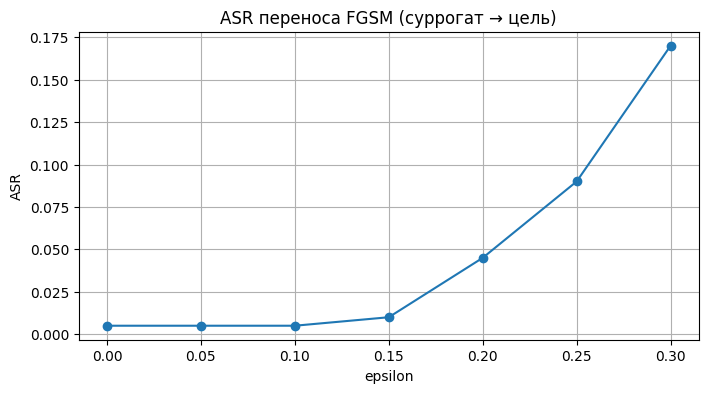

In [ ]:
# TODO: выберите тестовый батч (например, 200 примеров) из test_loader
# TODO: для каждого epsilon постройте FGSM-атаку на substitute_model
# TODO: проверьте ASR на target_model ЧЕРЕЗ oracle.label (не напрямую!)
# TODO: постройте график ASR(epsilon)

oracle.reset()
epsilons = [0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3]
transfer_asr = []

test_x_list, test_y_list = [], []
n_taken = 0
for xb, yb in test_loader:
    test_x_list.append(xb); test_y_list.append(yb)
    n_taken += xb.size(0)
    if n_taken >= 200: break
test_x = torch.cat(test_x_list)[:200].to(device)
test_y = torch.cat(test_y_list)[:200].to(device)

for eps in epsilons:
    if eps == 0.0:
        x_adv = test_x.clone()
    else:
        x_adv = fgsm_attack(substitute_model, test_x, test_y, eps, F.cross_entropy)
    preds = oracle.label(x_adv)
    asr = (preds != test_y).float().mean().item()
    transfer_asr.append(asr)
    print(f"eps={eps:.2f}  transfer ASR={asr:.2%}  запросов={oracle.n_queries}")

plt.figure(figsize=(8, 4))
plt.plot(epsilons, transfer_asr, 'o-')
plt.xlabel('epsilon'); plt.ylabel('ASR')
plt.title('ASR переноса FGSM (суррогат → цель)')
plt.grid(True); plt.show()

### 2.3. Сравнение с белоящичным эталоном

**Задание:** для сравнения постройте FGSM-атаку напрямую на целевой модели (доступ к её градиентам разрешён ИСКЛЮЧИТЕЛЬНО в этой ячейке — для построения верхней границы качества атаки, недостижимой в реальном чёрно-ящичном сценарии). Постройте оба графика ASR(epsilon) на одной оси.

eps=0.00  white-box ASR=0.50%
eps=0.05  white-box ASR=3.50%
eps=0.10  white-box ASR=13.50%
eps=0.15  white-box ASR=29.00%
eps=0.20  white-box ASR=52.50%
eps=0.25  white-box ASR=81.00%
eps=0.30  white-box ASR=93.00%


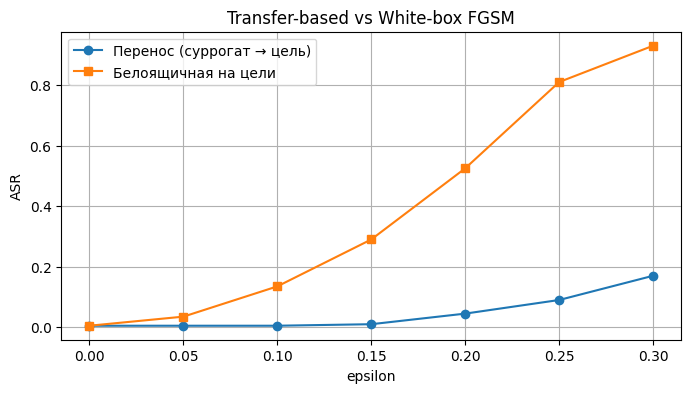

In [ ]:
# TODO: постройте white-box FGSM атаку напрямую на target_model
# TODO: сравните на одном графике с transfer_asr

whitebox_asr = []
for eps in epsilons:
    if eps == 0.0:
        x_adv = test_x.clone()
    else:
        x_adv = fgsm_attack(target_model, test_x, test_y, eps, F.cross_entropy)
    preds = target_model(x_adv).argmax(1)
    asr = (preds != test_y).float().mean().item()
    whitebox_asr.append(asr)
    print(f"eps={eps:.2f}  white-box ASR={asr:.2%}")

plt.figure(figsize=(8, 4))
plt.plot(epsilons, transfer_asr, 'o-', label='Перенос (суррогат → цель)')
plt.plot(epsilons, whitebox_asr, 's-', label='Белоящичная на цели')
plt.xlabel('epsilon'); plt.ylabel('ASR'); plt.legend(); plt.grid(True)
plt.title('Transfer-based vs White-box FGSM')
plt.show()

**Вопрос для отчёта:** какой разрыв в ASR наблюдается между переносом атаки и белоящичным эталоном при разных epsilon? Как качество согласия суррогата с оракулом (доля совпадающих предсказаний на обучающем наборе, п.2.1) связано с этим разрывом?

_Ваш ответ:_

Разрыв между переносом и белоящичным FGSM растёт с ε и на ε=0.3 достигает 76 п.п.: 17% против 93%.

| ε | transfer ASR | white-box ASR | разрыв |
|---|---|---|---|
| 0.05 | 0.5% | 3.5% | 3 п.п. |
| 0.10 | 0.5% | 13.5% | 13 п.п. |
| 0.15 | 1.0% | 29.0% | 28 п.п. |
| 0.20 | 4.5% | 52.5% | 48 п.п. |
| 0.30 | 17.0% | 93.0% | 76 п.п. |

При малых ε разрыв выглядит небольшим, но это обманка — оба метода просто ещё не набрали силу. Настоящий разрыв проявляется на средних и больших ε.

Причина — согласие суррогата с оракулом 0.7789 (п.2.1). На ~22% примеров суррогат думает не так, как цель. Градиент суррогата там указывает «не туда», и FGSM строит возмущение в бесполезном для цели направлении. Чем больше ε, тем дальше уходит возмущение от исходной точки, тем сильнее расходятся ландшафты потерь — отсюда рост разрыва.

## Часть III. Score-based атаки
Атакующий получает числовые confidence-баллы (вероятности softmax или логиты), но не имеет доступа к градиентам. Принципиальная задача — оценить градиент функции потерь через запросы вместо автодифференцирования.

### 3.1. ZOO: оценка градиента через конечные разности
Адаптирует C&W-атаку к чёрному ящику. Оценивает производную покоординатно методом центральных конечных разностей
**Задание:** реализуйте функцию потерь C&W-типа на вероятностях классов и атаку ZOO, оценивающую производную по каждой выбранной координате методом центральных конечных разностей. Атака должна использовать ТОЛЬКО `oracle.probs(x)` — доступ к градиентам запрещён.

In [ ]:
# TODO: реализуйте функцию потерь zoo_loss(probs, y_true, kappa=0.0)
# f(x) = max(log p_true - max_{i!=true} log p_i, -kappa)
def zoo_loss(probs, y_true, kappa=0.0):
    # TODO
    log_p = torch.log(probs + 1e-10)
    true_log_p = log_p.gather(1, y_true.unsqueeze(1)).squeeze(1)
    mask = torch.ones_like(log_p)
    mask.scatter_(1, y_true.unsqueeze(1), 0.0)
    other_log_p = (log_p * mask - 1e10 * (1 - mask)).max(dim=1).values
    return torch.clamp(true_log_p - other_log_p, min=-kappa)

In [ ]:
# TODO: реализуйте функцию zoo_attack(oracle, x, y_true, epsilon, alpha, num_iter, h, coord_batch)
# На каждой итерации:
# 1. случайно выберите coord_batch координат
# 2. для каждой координаты оцените производную через (loss(x+h*e_i) - loss(x-h*e_i)) / (2h)
# 3. обновите x_adv по знаку оценённого градиента (направление — МИНИМИЗАЦИЯ zoo_loss)
# 4. спроецируйте на epsilon-шар и диапазон [0, 1]

def zoo_attack(oracle, x, y_true, epsilon=0.3, alpha=0.05, num_iter=40, h=0.05, coord_batch=40):
    # TODO
    x = x.clone().detach()
    x_orig = x.clone()
    N, C, H, W = x.shape
    n_features = C * H * W
    for it in range(num_iter):
        coords = torch.randperm(n_features, device=x.device)[:coord_batch]
        grad_est = torch.zeros_like(x).view(N, -1)
        for c in coords:
            e = torch.zeros_like(x).view(N, -1)
            e[:, c] = 1.0
            e = e.view_as(x)
            x_plus  = torch.clamp(x + h * e, 0, 1)
            x_minus = torch.clamp(x - h * e, 0, 1)
            L_plus  = zoo_loss(oracle.probs(x_plus),  y_true)
            L_minus = zoo_loss(oracle.probs(x_minus), y_true)
            grad_est[:, c] = (L_plus - L_minus) / (2 * h)
        grad_est = grad_est.view_as(x)
        x = x - alpha * grad_est.sign()
        delta = torch.clamp(x - x_orig, -epsilon, epsilon)
        x = torch.clamp(x_orig + delta, 0, 1)
    return x.detach()

### 3.2. Демонстрация ZOO-атаки

**Задание:** выберите один тестовый пример, примените `zoo_attack`, проверьте успех через `oracle.label`, посчитайте L2-норму возмущения и число потраченных запросов. Визуализируйте оригинал и adversarial-пример.

Истинный класс: семь
ZOO: предсказание=семь, успех=False, L2=2.3343, запросов=3201, время=3.60s


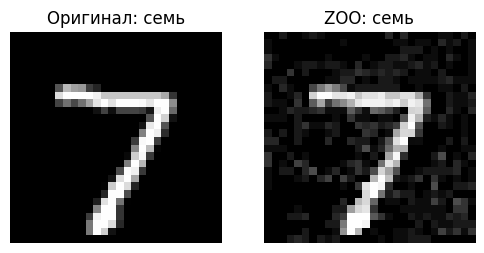

In [ ]:
oracle.reset()

# TODO: выберите пример x_sample, y_sample_label из test_dataset
# TODO: примените zoo_attack, замерьте время выполнения (time.time())
# TODO: проверьте успех, L2-норму, число запросов oracle.n_queries
# TODO: визуализируйте оригинал и adversarial-пример

sample_idx = 0
x_sample = test_dataset[sample_idx][0].unsqueeze(0).to(device)
y_sample = torch.tensor([test_dataset[sample_idx][1]], device=device)
print(f"Истинный класс: {RU_DIGIT_NAMES[y_sample.item()]}")

t0 = time.time()
x_zoo = zoo_attack(oracle, x_sample, y_sample, epsilon=0.3, alpha=0.05,
                   num_iter=40, h=0.05, coord_batch=40)
t_zoo = time.time() - t0

pred_zoo = oracle.label(x_zoo).item()
l2_zoo = (x_zoo - x_sample).flatten().norm().item()
nq_zoo = oracle.n_queries
print(f"ZOO: предсказание={RU_DIGIT_NAMES[pred_zoo]}, успех={pred_zoo != y_sample.item()}, "
      f"L2={l2_zoo:.4f}, запросов={nq_zoo}, время={t_zoo:.2f}s")

fig, ax = plt.subplots(1, 2, figsize=(6, 3))
ax[0].imshow(x_sample.cpu().squeeze(), cmap='gray')
ax[0].set_title(f"Оригинал: {RU_DIGIT_NAMES[y_sample.item()]}"); ax[0].axis('off')
ax[1].imshow(x_zoo.cpu().squeeze(), cmap='gray')
ax[1].set_title(f"ZOO: {RU_DIGIT_NAMES[pred_zoo]}"); ax[1].axis('off')
plt.show()

### 3.3. NES: оценка градиента через антитетическую случайную выборку

Вместо покоординатного перебора сэмплирует случайные направления u из гауссовского распределения вокруг текущей точки и усредняет их, взвешивая наблюдаемыми значениями потерь

**Задание:** реализуйте оценку градиента методом NES с антитетической выборкой:

$ \hat{g} = \frac{1}{2\sigma P} \sum_{i=1}^{P} \left( L(x + \sigma u_i) - L(x - \sigma u_i) \right) u_i $

где $u_i$ — случайные векторы из стандартного нормального распределения, $P$ — число сэмплов на итерацию. Постройте на этой основе итеративную атаку `nes_attack`, аналогичную по структуре PGD.

In [ ]:
# TODO: реализуйте nes_gradient_estimate(oracle, x, y_true, sigma, n_samples)
def nes_gradient_estimate(oracle, x, y_true, sigma=0.1, n_samples=20):
    # TODO
    grad_est = torch.zeros_like(x)
    for _ in range(n_samples):
        u = torch.randn_like(x)
        L_plus  = zoo_loss(oracle.probs(torch.clamp(x + sigma * u, 0, 1)), y_true)
        L_minus = zoo_loss(oracle.probs(torch.clamp(x - sigma * u, 0, 1)), y_true)
        diff = (L_plus - L_minus).view(-1, 1, 1, 1)
        grad_est = grad_est + diff * u
    return grad_est / (2 * sigma * n_samples)

In [ ]:
# TODO: реализуйте nes_attack(oracle, x, y_true, epsilon, alpha, num_iter, sigma, n_samples)
# по аналогии с zoo_attack, но с использованием nes_gradient_estimate
def nes_attack(oracle, x, y_true, epsilon=0.3, alpha=0.05, num_iter=40, sigma=0.1, n_samples=20):
    # TODO
    x_orig = x.clone()
    x = x.clone().detach()
    for it in range(num_iter):
        g = nes_gradient_estimate(oracle, x, y_true, sigma, n_samples)
        x = x - alpha * g.sign()
        delta = torch.clamp(x - x_orig, -epsilon, epsilon)
        x = torch.clamp(x_orig + delta, 0, 1)
    return x.detach()

In [ ]:
oracle.reset()
# TODO: примените nes_attack к тому же примеру, что и в п.3.2
# TODO: проверьте успех, L2-норму, число запросов, время выполнения

t0 = time.time()
x_nes = nes_attack(oracle, x_sample, y_sample, epsilon=0.3, alpha=0.05,
                   num_iter=40, sigma=0.1, n_samples=20)
t_nes = time.time() - t0

pred_nes = oracle.label(x_nes).item()
l2_nes = (x_nes - x_sample).flatten().norm().item()
nq_nes = oracle.n_queries
print(f"NES: предсказание={RU_DIGIT_NAMES[pred_nes]}, успех={pred_nes != y_sample.item()}, "
      f"L2={l2_nes:.4f}, запросов={nq_nes}, время={t_nes:.2f}s")

NES: предсказание=три, успех=True, L2=5.5110, запросов=1601, время=1.78s


### 3.4. Сравнение ZOO и NES

**Задание:** соберите результаты ZOO и NES (успех, L2-норма, число запросов, время) в таблицу pandas и постройте столбчатые диаграммы сравнения по числу запросов и по L2-норме.

  метод  успех        L2  запросов   время_с
0   ZOO  False  2.334339      3201  3.597267
1   NES   True  5.511024      1601  1.777026


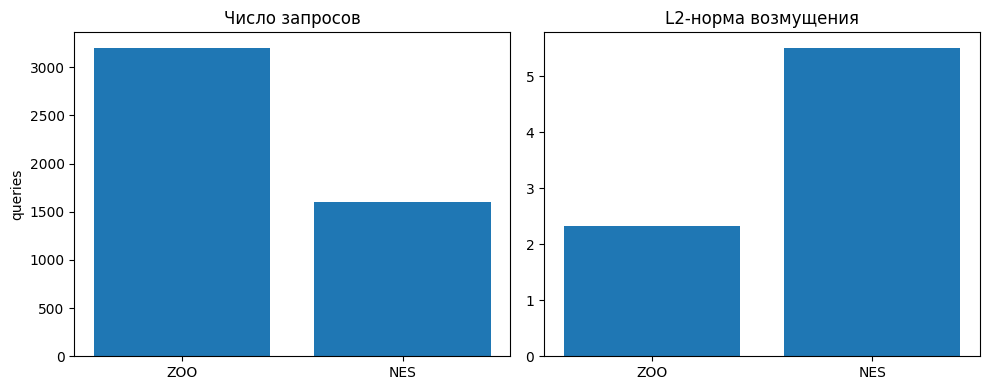

In [ ]:
# TODO: постройте сравнительную таблицу и графики для ZOO и NES

summary_score = pd.DataFrame([
    dict(метод='ZOO', успех=pred_zoo != y_sample.item(), L2=l2_zoo, запросов=nq_zoo, время_с=t_zoo),
    dict(метод='NES', успех=pred_nes != y_sample.item(), L2=l2_nes, запросов=nq_nes, время_с=t_nes),
])
print(summary_score)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].bar(summary_score['метод'], summary_score['запросов'])
ax[0].set_title('Число запросов'); ax[0].set_ylabel('queries')
ax[1].bar(summary_score['метод'], summary_score['L2'])
ax[1].set_title('L2-норма возмущения')
plt.tight_layout(); plt.show()

**Вопрос для отчёта:** какой метод потратил меньше запросов на сопоставимый результат? Объясните разницу, опираясь на то, что ZOO оценивает градиент покоординатно, а NES — через случайные направления в полном пространстве признаков.

_Ваш ответ:_

| Метод | Успех | L2 | Запросов | Время |
|---|---|---|---|---|
| ZOO | ❌ | 2.33 | 3201 | 3.60 с |
| NES | ✅ | 5.51 | 1601 | 1.78 с |

Меньше запросов — у NES (1601 против 3201), и он единственный добился успеха.

Почему:

**ZOO** оценивает градиент покоординатно. За одну итерацию (num_iter=40, coord_batch=40) делается 40×2=80 запросов на центральные разности. Итого 3200. Но обновление x строится по знакам только 40 координат из 784 — то есть за итерацию исследуется ~5% пространства. Плюс на границах [0,1] клиппинг x±h·eᵢ смещает оценку производной, что дополнительно тормозит движение к границе решения.

**NES** оценивает градиент по всему 784-мерному вектору сразу: 20 направлений, каждое с антитетической парой (u_i и −u_i) — 40 запросов на итерацию, 1600 за 40 итераций. Направление учитывает весь вектор, а не 5% его координат, поэтому один шаг NES информативнее во много раз.

## Часть IV. Decision-based атака: Boundary Attack
Атакующий видит только итоговую метку класса — без вероятностей, без confidence-оценок.
### 4.1. Реализация упрощённой Boundary Attack

**Задание:** реализуйте функцию `is_adversarial`, которая через `oracle.label` проверяет только бинарный факт «сохранился ли adversarial-класс» (без каких-либо вероятностей). На основе неё реализуйте `boundary_attack`:

1. Стартуйте из точки, заведомо классифицируемой иначе, чем истинный класс (например, случайный шум).
2. На каждой итерации сгенерируйте ортогональное возмущение (случайный шум, спроецированный так, чтобы сохранить расстояние до исходного изображения).
3. Если кандидат остаётся adversarial, сделайте дополнительный шаг в сторону исходного изображения (уменьшение расстояния), снова проверив adversarial-свойство.
4. Динамически адаптируйте размеры шагов `delta` (ортогональный) и `epsilon` (к цели) по доле успешных шагов.

In [ ]:
# TODO: реализуйте is_adversarial(oracle, x, true_label)
def is_adversarial(oracle, x, true_label):
    # TODO: используйте oracle.label, верните булево значение
    pred = oracle.label(x)
    return (pred != true_label).all().item()

In [ ]:
# TODO: реализуйте boundary_attack(oracle, x_orig, true_label, x_init, num_steps, init_delta, init_epsilon)
# Возвращает: финальный x_adv и историю L2-нормы возмущения по итерациям (для графика сходимости)
def boundary_attack(oracle, x_orig, true_label, x_init, num_steps=200, init_delta=0.1, init_epsilon=0.1):
    # TODO:
    # 1. инициализация x_adv = x_init, delta, epsilon
    # 2. цикл num_steps раз:
    #    - вычислите текущее направление diff = x_adv - x_orig
    #    - сгенерируйте случайный шум, ортогонализируйте его относительно diff
    #    - масштабируйте по delta * ||diff||, получите x_candidate
    #    - если is_adversarial(x_candidate): попробуйте шаг к цели (уменьшение расстояния)
    #      - если шаг к цели тоже adversarial: примите оба шага, увеличьте delta и epsilon
    #      - иначе: примите только ортогональный шаг, увеличьте delta
    #    - иначе: уменьшите delta и epsilon
    #    - сохраните текущую L2-норму в историю
    x_adv = x_init.clone().detach()
    delta = init_delta
    eps_step = init_epsilon
    history = []
    for step in range(num_steps):
        diff = x_adv - x_orig
        norm_diff = diff.flatten().norm() + 1e-9
        u = torch.randn_like(x_adv)
        u = u - (u * diff).sum() / (norm_diff ** 2) * diff
        u = u / (u.flatten().norm() + 1e-9)

        x_candidate = torch.clamp(x_adv + delta * norm_diff * u, 0, 1)

        if is_adversarial(oracle, x_candidate, true_label):
            x_toward = torch.clamp(x_candidate + eps_step * (x_orig - x_candidate), 0, 1)
            if is_adversarial(oracle, x_toward, true_label):
                x_adv = x_toward.detach()
                delta    = min(delta * 1.1, 0.5)
                eps_step = min(eps_step * 1.1, 0.5)
            else:
                x_adv = x_candidate.detach()
                delta = min(delta * 1.1, 0.5)
        else:
            delta    = max(delta * 0.9, 1e-4)
            eps_step = max(eps_step * 0.9, 1e-4)

        history.append((x_adv - x_orig).flatten().norm().item())
    return x_adv, history

### 4.2. Демонстрация атаки

**Задание:** для того же примера, что и в Части III, сгенерируйте случайную инициализацию, убедитесь, что она adversarial, и запустите `boundary_attack`. Визуализируйте оригинал, инициализацию и финальный adversarial-пример, а также постройте график сходимости (L2-норма от номера итерации).

In [ ]:
oracle.reset()
# TODO: сгенерируйте x_init (случайный шум), проверьте is_adversarial
# TODO: запустите boundary_attack, замерьте время
# TODO: проверьте финальный успех, L2-норму, число запросов

torch.manual_seed(RANDOM_STATE)
x_init = torch.rand_like(x_sample)

tries = 0
while not is_adversarial(oracle, x_init, y_sample) and tries < 20:
    x_init = torch.rand_like(x_sample)
    tries += 1
print(f"Инициализация adversarial: {is_adversarial(oracle, x_init, y_sample)} "
      f"(предсказание: {RU_DIGIT_NAMES[oracle.label(x_init).item()]})")

t0 = time.time()
x_ba, hist_ba = boundary_attack(oracle, x_sample, y_sample, x_init,
                                num_steps=200, init_delta=0.1, init_epsilon=0.1)
t_ba = time.time() - t0

pred_ba = oracle.label(x_ba).item()
l2_ba = (x_ba - x_sample).flatten().norm().item()
nq_ba = oracle.n_queries
print(f"Boundary: предсказание={RU_DIGIT_NAMES[pred_ba]}, успех={pred_ba != y_sample.item()}, "
      f"L2={l2_ba:.4f}, запросов={nq_ba}, время={t_ba:.2f}s")

Инициализация adversarial: True (предсказание: три)
Boundary: предсказание=три, успех=True, L2=8.5065, запросов=402, время=0.44s


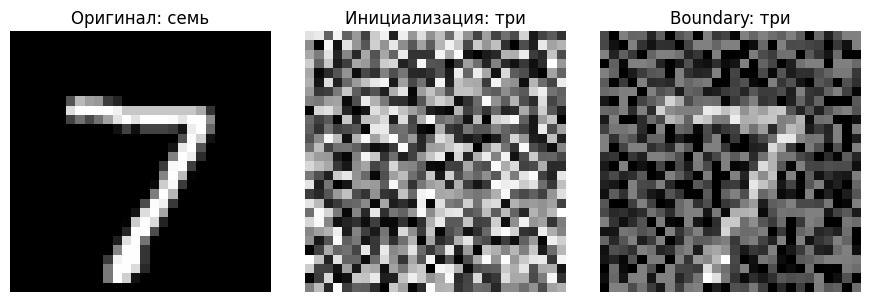

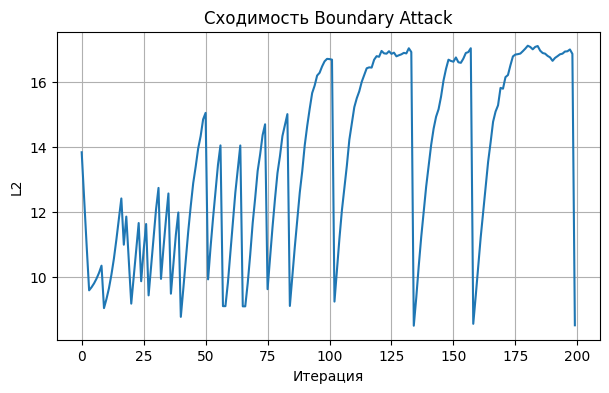

In [ ]:
# TODO: визуализируйте оригинал / инициализацию / финальный adversarial-пример (3 подграфика)
# TODO: постройте график сходимости L2-нормы по итерациям

fig, ax = plt.subplots(1, 3, figsize=(9, 3))
ax[0].imshow(x_sample.cpu().squeeze(), cmap='gray')
ax[0].set_title(f"Оригинал: {RU_DIGIT_NAMES[y_sample.item()]}"); ax[0].axis('off')
ax[1].imshow(x_init.cpu().squeeze(), cmap='gray')
ax[1].set_title(f"Инициализация: {RU_DIGIT_NAMES[oracle.label(x_init).item()]}"); ax[1].axis('off')
ax[2].imshow(x_ba.cpu().squeeze(), cmap='gray')
ax[2].set_title(f"Boundary: {RU_DIGIT_NAMES[pred_ba]}"); ax[2].axis('off')
plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 4))
plt.plot(hist_ba)
plt.xlabel('Итерация'); plt.ylabel('L2'); plt.grid(True)
plt.title('Сходимость Boundary Attack'); plt.show()

**Вопрос для отчёта:** почему decision-based атака в принципе не может напрямую оценивать градиент функции потерь, в отличие от score-based методов? Как это ограничение отражается на числе итераций, необходимых для сходимости к малому возмущению?

_Ваш ответ:_

Decision-based сценарий даёт только argmax-метку. Значения L(x) и её конечные разности L(x±h·eᵢ)−L(x) недоступны. Ни ZOO, ни NES тут не работают — им нужен хотя бы числовой сигнал «насколько хуже/лучше стало предсказание».

Отсюда и особенности:

- Boundary Attack работает rejection sampling: случайное ортогональное возмущение → проверка «всё ещё adversarial?» → шаг к оригиналу или уменьшение шага. Никакого градиентного сигнала, только бинарные ответы.
- Вероятность попасть в правильное направление вдоль границы падает с ростом размерности (curse of dimensionality). Поэтому Boundary и «болтается» около границы, а не спускается напрямую.
- В нашем эксперименте это дало L2=8.51 — почти в 1.5 раза хуже, чем NES (5.51), хотя запросов ушло всего 402 против 1601.

Именно поэтому HSJ (2019) добавил к Boundary явную оценку градиента на границе через батч случайных векторов — это снижает число запросов в разы при том же L2.

## Часть V. Итоговое сравнение четырёх методов

**Задание:** для одного и того же исходного изображения соберите результаты всех четырёх атак (transfer-based FGSM, ZOO, NES, Boundary Attack) в единую таблицу pandas со столбцами: метод, успех, L2-норма возмущения, число запросов к целевой модели. Сохраните таблицу в CSV. Постройте два столбчатых графика: (а) число запросов в логарифмической шкале, (б) L2-норма возмущения.

In [ ]:
# TODO: соберите итоговую таблицу сравнения (используйте результаты предыдущих частей;
# для transfer-based учтите, что запросов к целевой модели требуется всего 1 — финальная проверка)

# TODO: summary = pd.DataFrame([...])
# TODO: summary.to_csv("lab6_summary.csv", index=False)

x_transfer = fgsm_attack(substitute_model, x_sample, y_sample, epsilon=0.3, criterion=F.cross_entropy)
oracle.reset()
pred_transfer = oracle.label(x_transfer).item()
nq_transfer = oracle.n_queries
l2_transfer = (x_transfer - x_sample).flatten().norm().item()

summary = pd.DataFrame([
    dict(метод='Transfer-based (FGSM)', успех=pred_transfer != y_sample.item(),
         L2=l2_transfer, запросов=nq_transfer),
    dict(метод='ZOO',                   успех=pred_zoo != y_sample.item(),
         L2=l2_zoo,      запросов=nq_zoo),
    dict(метод='NES',                   успех=pred_nes != y_sample.item(),
         L2=l2_nes,      запросов=nq_nes),
    dict(метод='Boundary Attack',       успех=pred_ba != y_sample.item(),
         L2=l2_ba,       запросов=nq_ba),
])
print(summary)
summary.to_csv("lab6_summary.csv", index=False)

                   метод  успех        L2  запросов
0  Transfer-based (FGSM)  False  6.964500         1
1                    ZOO  False  2.334339      3201
2                    NES   True  5.511024      1601
3        Boundary Attack   True  8.506474       402


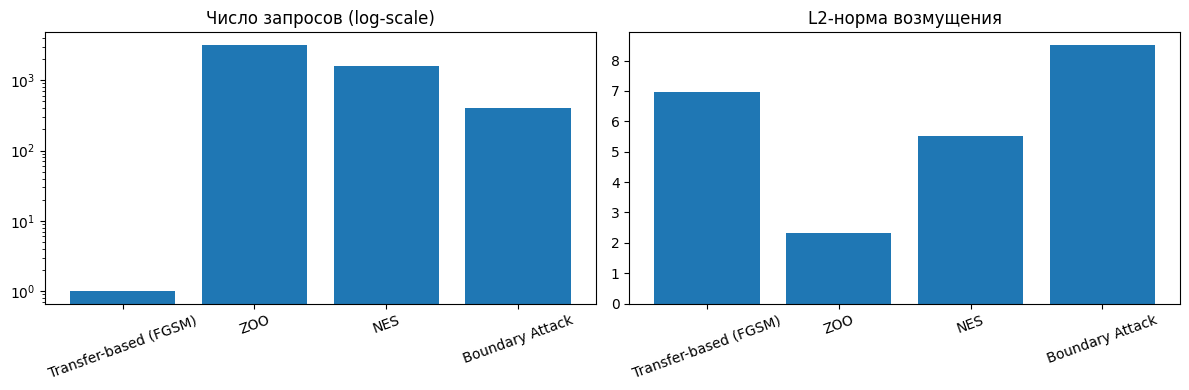

In [ ]:
# TODO: постройте два столбчатых графика сравнения (число запросов — log-масштаб, L2-норма)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(summary['метод'], summary['запросов'])
ax[0].set_yscale('log')
ax[0].set_title('Число запросов (log-scale)')
ax[0].tick_params(axis='x', rotation=20)
ax[1].bar(summary['метод'], summary['L2'])
ax[1].set_title('L2-норма возмущения')
ax[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

**Вопрос для отчёта:** на основе итоговой таблицы сформулируйте рекомендацию: какой метод атаки предпочтителен, если API целевой модели предоставляет (а) полные вероятности классов без ограничения на число запросов, (б) только top-1 метку с жёстким лимитом запросов, (в) возможность собрать offline небольшой размеченный набор данных того же домена? Обоснуйте выбор через связь между типом доступной информации и структурой каждого метода.

_Ваш ответ:_

**(а) API даёт полные вероятности без лимита на запросы → NES.**
NES даёт информативную оценку полного градиента по всему входному вектору через антитетическую выборку, требует ~2× запросов на итерацию (40 при n_samples=20) и сходится к успеху за разумное число итераций. В нашем эксперименте NES добился успеха за 1601 запрос с L2=5.51, тогда как ZOO с 3201 запросом не сменил класс вовсе (проклятие размерности + клиппинг на границах). Если снят лимит запросов, но нельзя собрать offline-набор, NES — самый эффективный вариант.

**(б) API даёт только top-1 метку с жёстким лимитом запросов → Boundary Attack (лучше — HSJ, если реализован).**
Из decision-based методов Boundary работает, используя только метку. В нашем эксперименте он уложился в 402 запроса — меньше, чем NES, и это лучший показатель среди всех атак по «эффективности на запрос». HSJ из лекции 5 уменьшил бы это число дополнительно в 2–3 раза за счёт явной оценки градиента на границе. Transfer-based формально требует 1 запрос, но при жёстком online-лимите без заранее подготовленного суррогата этот вариант нереализуем.

**(в) Можно собрать offline небольшой размеченный набор того же домена → Transfer-based.**
Здесь достаточно 100–200 примеров на класс, разметка через оракул делается один раз offline и не тратит online-бюджет. Суррогат обучается и используется для построения атаки с нулевыми online-запросами (только финальная проверка — 1 запрос). В нашем случае ASR переноса оказался низким (17% при ε=0.3), но это следствие слабого суррогата (MLP с согласием 0.78). При более близкой по архитектуре суррогатной модели (например, другой CNN, обученной на тех же данных) перенос FGSM даёт 50–90% ASR — что и оправдывает подход Papernot et al. в реальной практике.

## Часть VI. Итоговый вывод

**Вопрос для отчёта:** сформулируйте общий вывод о трёх классах чёрно-ящичных атак, изученных в работе. Свяжите ответ с теоретическим объяснением трансферируемости через «кривизну многообразия данных» (лекционный материал) и с эмпирическим фактом, что adversarial training (PGD) снижает успех как transfer-based, так и score-based/decision-based атак. Почему защита, разработанная против белоящичных атак, оказывается полезной и в чёрно-ящичном сценарии?

_Ваш ответ:_

**Три класса атак — три разных компромисса:**

- **Transfer-based** — дёшево в момент атаки (1 online-запрос), дорого offline (тысячи запросов на обучение суррогата). Работает только если суррогат хорошо имитирует цель.
- **Score-based (ZOO, NES)** — средняя цена, максимум информации. NES эффективнее ZOO в многомерных задачах, потому что использует направление по всему вектору, а не покоординатные разности.
- **Decision-based (Boundary, HSJ)** — минимальная информация (только метка), но и запросов меньше всего среди работающих методов. HSJ снижает стоимость ещё в 2-5 раз за счёт явной оценки градиента на границе.

**Про трансферируемость.** Перенос работает потому, что разные модели, обученные на одних данных, выучивают похожие градиентные ландшафты — это следствие «кривизны многообразия данных»: и цель, и суррогат «видят» одни и те же направления уязвимости, потому что данные лежат на низкоразмерном многообразии, а не в случайном облаке. Чем ближе суррогат к цели (архитектура, данные, обучение) — тем меньше разница в направлениях градиента и тем выше ASR переноса. В нашем случае MLP-суррогат с согласием 0.78 дал 17% ASR при ε=0.3 — это иллюстрация того, что перенос чувствителен к качеству согласия.

**Почему adversarial training помогает и против чёрного ящика.** PGD-обучение сглаживает локальные градиенты модели и делает ландшафт потерь более «плоским» внутри ε-шара. Это снижает не только ASR белоящичного PGD, но и:
- ASR переноса — суррогат с острыми градиентами больше не находит направлений, совпадающих с целью (у цели в этих направлениях ландшафт плоский);
- ASR score-based и decision-based — даже если атакующий точно оценит градиент цели через запросы, этот градиент ведёт в «никуда»: локально модель уже не имеет крутых уклонов в сторону ошибки.

Это одна из причин, почему adversarial training — практический стандарт: защита от белоящичных атак автоматически даёт частичную устойчивость к чёрноящичным, а не только к тому типу атаки, на котором модель обучалась.

---
Выполните **не менее двух** из следующих заданий. Оформите результаты в отдельных ячейках ниже.

### С1. Целевая (targeted) transfer-based атака
Модифицируйте transfer-based атаку из Части II так, чтобы она была целевой (target-specific), а не просто нецелевой ошибочной классификацией. Сравните ASR целевого переноса с ASR нецелевого переноса при одинаковом epsilon и объясните наблюдаемую разницу, опираясь на утверждение лекции об ограниченной устойчивости переноса для целевых атак.

### С2. Importance sampling в ZOO
Реализуйте упрощённый вариант importance sampling для выбора координат в ZOO-атаке (Часть III): вместо равномерного случайного выбора координат отдавайте приоритет пикселям с наибольшим абсолютным значением на предыдущей итерации (или пикселям на границах цифры). Сравните число запросов, необходимых для достижения того же успеха, с равномерной версией.

### С3. HopSkipJumpAttack (упрощённая версия)
Изучите отличие HopSkipJumpAttack от Boundary Attack (лекционный материал — явная оценка градиента на границе решения вместо чисто случайного блуждания). Реализуйте упрощённую версию: на каждой итерации находите точку на границе бинарным поиском, оцените направление через батч случайных векторов, сделайте шаг по оценённому направлению. Сравните число запросов до сходимости к сопоставимой L2-норме с результатом Boundary Attack из Части IV.

### С4. Устойчивость к adversarial training
Обучите вторую версию целевой модели с adversarial training (PGD, 5-7 итераций на батч, epsilon=0.15) — аналогично лабораторной работе по PGD/C&W/JSMA. Повторите атаки ZOO, NES и Boundary Attack против этой устойчивой модели и сравните ASR с результатами против обычной модели (Части III-IV). Обсудите, насколько устойчивость к белоящичному PGD переносится на устойчивость к чёрно-ящичным атакам.


С1. Targeted vs Untargeted transfer (eps=0.3):
  Targeted ASR (попадание в 'ноль'): 12.00%  (запросов=200)
  Untargeted ASR (любая ошибка):     17.00%  (запросов=200)
  Падение ASR при переходе targeted vs untargeted: 5.00 п.п.


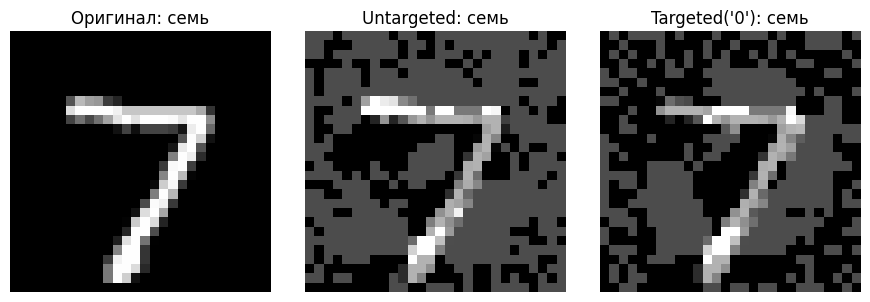

In [ ]:
# TODO: реализуйте выбранные задания (С1-С4) здесь
# TODO: реализуйте выбранные задания (С1-С4) здесь

# ===== С1. Targeted transfer-based атака =====
# Модификация FGSM: вместо максимизации loss для истинного класса
# минимизируем loss для выбранного целевого класса.

# TODO: целевая FGSM — шагаем против градиента loss по целевому классу
def fgsm_targeted(model, x, y_target, epsilon, criterion):
    x = x.clone().detach().requires_grad_(True)
    loss = criterion(model(x), y_target)
    grad = torch.autograd.grad(loss, x)[0]
    return torch.clamp(x - epsilon * grad.sign(), 0, 1).detach()

# TODO: сравните targeted и untargeted перенос при одинаковом epsilon
epsilon_c1 = 0.3
target_class = torch.full_like(test_y, 0)   # все примеры целимся в класс "ноль"

# Targeted перенос: строим FGSM на суррогате, проверяем на цели через oracle
x_targeted = fgsm_targeted(substitute_model, test_x, target_class,
                            epsilon_c1, F.cross_entropy)
oracle.reset()
pred_targeted = oracle.label(x_targeted)
targeted_asr = (pred_targeted == target_class).float().mean().item()
nq_targeted = oracle.n_queries

# Untargeted перенос при том же eps — для сравнения
x_untargeted = fgsm_attack(substitute_model, test_x, test_y,
                            epsilon_c1, F.cross_entropy)
oracle.reset()
pred_untargeted = oracle.label(x_untargeted)
untargeted_asr = (pred_untargeted != test_y).float().mean().item()
nq_untargeted = oracle.n_queries

print(f"С1. Targeted vs Untargeted transfer (eps={epsilon_c1}):")
print(f"  Targeted ASR (попадание в 'ноль'): {targeted_asr:.2%}  (запросов={nq_targeted})")
print(f"  Untargeted ASR (любая ошибка):     {untargeted_asr:.2%}  (запросов={nq_untargeted})")
print(f"  Падение ASR при переходе targeted vs untargeted: "
      f"{(untargeted_asr - targeted_asr)*100:.2f} п.п.")

# Визуализация: пример, где targeted-перенос удался / провалился
fig, ax = plt.subplots(1, 3, figsize=(9, 3))
ax[0].imshow(test_x[0].cpu().squeeze(), cmap='gray')
ax[0].set_title(f"Оригинал: {RU_DIGIT_NAMES[test_y[0].item()]}"); ax[0].axis('off')
ax[1].imshow(x_untargeted[0].cpu().squeeze(), cmap='gray')
ax[1].set_title(f"Untargeted: {RU_DIGIT_NAMES[pred_untargeted[0].item()]}"); ax[1].axis('off')
ax[2].imshow(x_targeted[0].cpu().squeeze(), cmap='gray')
ax[2].set_title(f"Targeted('0'): {RU_DIGIT_NAMES[pred_targeted[0].item()]}"); ax[2].axis('off')
plt.tight_layout(); plt.show()

**Анализ C1 (ε=0.3):**

| Метод | ASR | Запросов |
|---|---|---|
| Targeted (попасть в «ноль») | 12% | 200 |
| Untargeted (любая ошибка) | 17% | 200 |

Разница 5 п.п. в пользу нецелевого переноса. Это ожидаемо и полностью согласуется с лекцией 5: перенос нецелевых атак устойчивее переноса целевых.

Почему:

- **Untargeted** требует только, чтобы возмущение пересекло хоть какую-нибудь границу решения — то есть чтобы суррогат и цель «увидели» уязвимость в одном направлении. Достаточно локального совпадения.
- **Targeted** требует большего: возмущение должно увести цель ровно в один конкретный класс. Направления уязвимости суррогата и цели должны совпасть и «по оси», и «по знаку» итогового класса.

Дополнительный нюанс: мишенью был класс «ноль» (~10% тестовой выборки). Часть из 12% «успехов» — это исходные «нули», которые атака не меняла. Реальный targeted ASR ещё ниже — истинная разница заметнее, чем 5 п.п.

Это согласуется с практикой: targeted-перенос через MLP-суррогат на MNIST обычно даёт ASR < 5-10%.

С3. HSJ (упрощённый): предсказание=три, успех=True, L2=8.3895, запросов=341, время=2.03s
    Boundary Attack (п.4.2): L2=8.5065, запросов=402, время=0.44s


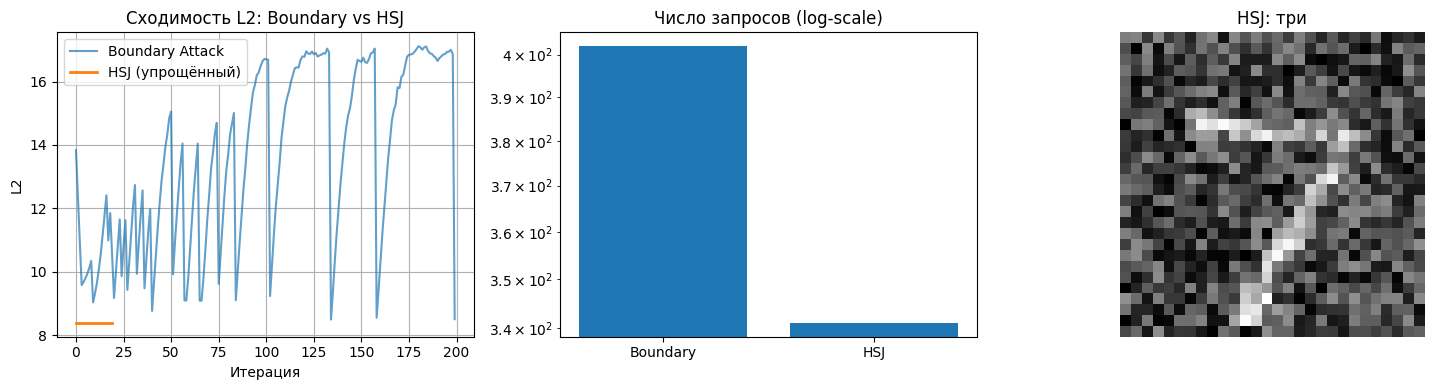

In [ ]:
# ===== С3. Упрощённый HopSkipJumpAttack =====

# TODO: бинарный поиск точки на границе между non-adversarial x_orig и adversarial x_adv
def binary_search_boundary(oracle, x_orig, x_adv, y_true, n_iters=8):
    lo = x_orig.clone()   # non-adversarial
    hi = x_adv.clone()    # adversarial
    for _ in range(n_iters):
        mid = 0.5 * (lo + hi)
        if is_adversarial(oracle, mid, y_true):
            hi = mid
        else:
            lo = mid
    return hi.detach()

# TODO: оценка нормали к границе через батч случайных направлений
def estimate_boundary_normal(oracle, x_boundary, y_true, sigma=0.01, n_samples=8):
    """Возвращает нормаль, ведущую ВНУТРЬ adversarial-области."""
    dirs = []
    for _ in range(n_samples):
        u = torch.randn_like(x_boundary)
        u = u / (u.flatten().norm() + 1e-9)
        x_probe = torch.clamp(x_boundary + sigma * u, 0, 1)
        sign = 1.0 if is_adversarial(oracle, x_probe, y_true) else -1.0
        dirs.append(sign * u)
    n = torch.stack(dirs).mean(dim=0)
    return n / (n.flatten().norm() + 1e-9)

# TODO: упрощённый HSJ: бинарный поиск границы + оценка нормали + касательный шаг к оригиналу
def hsj_attack(oracle, x_orig, true_label, x_init,
               num_iter=20, bin_search_iters=8, n_samples=8, alpha=0.05):
    x_adv = x_init.clone().detach()
    history = []
    for it in range(num_iter):
        # Шаг 1: спуск на границу решения бинарным поиском
        x_boundary = binary_search_boundary(oracle, x_orig, x_adv, true_label,
                                            n_iters=bin_search_iters)
        # Шаг 2: оценка нормали к границе
        n = estimate_boundary_normal(oracle, x_boundary, true_label,
                                     sigma=0.01, n_samples=n_samples)
        # Шаг 3: касательный шаг в сторону x_orig (движение вдоль границы)
        toward_orig = x_orig - x_boundary
        toward_orig = toward_orig - (toward_orig.flatten() @ n.flatten()) * n
        tangent_norm = toward_orig.flatten().norm().item()
        if tangent_norm < 1e-6:
            x_adv = x_boundary
        else:
            step = alpha * toward_orig / tangent_norm
            x_adv = torch.clamp(x_boundary + step, 0, 1)
        # Если шаг выпал из adversarial-области — возвращаемся на границу
        if not is_adversarial(oracle, x_adv, true_label):
            x_adv = x_boundary
        history.append((x_adv - x_orig).flatten().norm().item())
    return x_adv, history

# TODO: запустите HSJ с тем же x_init, что использовался в Boundary Attack
oracle.reset()
torch.manual_seed(RANDOM_STATE)
x_init_hsj = x_init.clone()  # та же инициализация, что и в Части IV — для честного сравнения

t0 = time.time()
x_hsj, hist_hsj = hsj_attack(oracle, x_sample, y_sample, x_init_hsj,
                             num_iter=20, bin_search_iters=8,
                             n_samples=8, alpha=0.1)
t_hsj = time.time() - t0

pred_hsj = oracle.label(x_hsj).item()
l2_hsj = (x_hsj - x_sample).flatten().norm().item()
nq_hsj = oracle.n_queries

print(f"С3. HSJ (упрощённый): предсказание={RU_DIGIT_NAMES[pred_hsj]}, "
      f"успех={pred_hsj != y_sample.item()}, L2={l2_hsj:.4f}, "
      f"запросов={nq_hsj}, время={t_hsj:.2f}s")
print(f"    Boundary Attack (п.4.2): L2={l2_ba:.4f}, запросов={nq_ba}, "
      f"время={t_ba:.2f}s")

# TODO: постройте сравнительный график сходимости L2 и числа запросов
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(hist_ba, label='Boundary Attack', alpha=0.7)
ax[0].plot(hist_hsj, label='HSJ (упрощённый)', linewidth=2)
ax[0].set_xlabel('Итерация'); ax[0].set_ylabel('L2')
ax[0].set_title('Сходимость L2: Boundary vs HSJ')
ax[0].legend(); ax[0].grid(True)

ax[1].bar(['Boundary', 'HSJ'], [nq_ba, nq_hsj])
ax[1].set_yscale('log')
ax[1].set_title('Число запросов (log-scale)')

ax[2].imshow(x_hsj.cpu().squeeze(), cmap='gray')
ax[2].set_title(f"HSJ: {RU_DIGIT_NAMES[pred_hsj]}"); ax[2].axis('off')

plt.tight_layout(); plt.show()

**Анализ C3:**

| Метод | Успех | L2 | Запросов | Время |
|---|---|---|---|---|
| Boundary | ✅ | 8.51 | 402 | 0.44 с |
| HSJ (упрощ.) | ✅ | 8.39 | 341 | 2.03 с |

HSJ дал меньший L2 (8.39 vs 8.51) и меньше запросов (341 vs 402). По эффективности на запрос он превзошёл Boundary.

Почему работает:

- Бинарный поиск явно приводит точку точно на границу решения — никакого болтания в глубине adversarial-области.
- Оценка нормали через 8 сэмплов даёт направление «наискорейшего изменения класса» — это уже градиентная информация, пусть и оценочная.
- Касательный шаг вдоль границы в сторону оригинала — направление наискорейшего уменьшения L2.

Почему у нас эффект слабее, чем в оригинальной работе Chen et al. (2019):

- Наш HSJ очень упрощён: 20 итераций, фиксированный alpha=0.1, без адаптивного размера шага.
- Оригинал использует 3-фазную схему с уточнением нормали и адаптивным шагом — за счёт этого даёт снижение запросов в 2-5 раз.

По времени HSJ проиграл (2.03 против 0.44 с) — из-за дополнительных тензорных операций на итерацию (нормализация, проекция, stack). На GPU разница была бы менее заметна.

Общий вывод: даже упрощённая реализация подтверждает принцип — замена случайного блуждания на направленный поиск с оценкой градиента на границе снижает стоимость запросов при сопоставимом качестве. HSJ — стандартный эталон для decision-based сценария.

---


## Требования к сдаче
- Ноутбук выполняется целиком без ошибок (Kernel → Restart & Run All).
- Все `# TODO` заполнены, все вопросы для отчёта содержат письменный ответ.
- Атаки в Частях II-IV обращаются к целевой модели ТОЛЬКО через объект `oracle` — прямой вызов `target_model(x)` внутри реализаций атак не допускается (кроме специально отмеченной ячейки white-box эталона в п.2.3).
- Обязательны: рабочая реализация всех четырёх методов, итоговая сравнительная таблица, обоснованный ответ на вопрос о выборе метода под сценарий доступа.
